![](img/banner.png)

# k-Means: Objective, Lemmas and Lloyd's Algorithm

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad


This page is the theory companion of [Clustering](Clustering-Part1.ipynb): there
scikit-learn is used to cluster digits and colours, and the algorithm is treated mostly as
a black box. Here we ask what k-means actually minimizes, why the objective never
increases, and how to write the algorithm from scratch.

**Learning objectives.** By the end you should be able to

1. write down the k-means objective and say what $n$, $d$ and $k$ are in it;
2. prove the two identities behind the algorithm: that the centroid minimizes the sum of
   squared distances (Lemma 1, with its corollary), and that the same quantity can be
   computed from pairwise distances (Lemma 2);
3. prove that Lloyd's algorithm terminates;
4. implement it safely — bounded iterations, empty clusters, a good initialization;
5. explain why the result is a local and not necessarily a global minimum, and how
   k-means++ improves the initialization.

## Definition of Clustering

A clustering of a set of datapoints $\{\mathbf{x}_1, \mathbf{x}_2, \ldots, \mathbf{x}_n\}$
is a partition of the datapoints into $k$ disjoint subsets (or clusters)
$\mathcal{C} = \{C_1, C_2, \ldots, C_k\}$ in such a way that datapoints in the same group
are more similar (in some specific sense defined by the analyst) to each other than to
those in other groups.

## Representative-based Clustering

Given a dataset with $n$ points in a $d$-dimensional space,
$\mathbf{D} = \{\mathbf{x}_i\}_{i=1}^n$, and given the number of desired clusters $k$, the
goal of representative-based clustering is to partition the dataset into $k$ groups or
clusters, which is called a **clustering** and is denoted as
$\mathcal{C} = \{C_1, C_2, \ldots, C_k\}$.

For each cluster $C_i$ there exists a representative point that summarizes the cluster, a
common choice being the mean (also called the *centroid*) $\mu_i$ of all points in the
cluster, that is,

$$
\mu_i = \frac{1}{n_i} \sum_{\mathbf{x}_j \in C_i} \mathbf{x}_j
$$

where $n_i = |C_i|$ is the number of points in cluster $C_i$.

## The k-means Objective

k-means is a representative-based clustering method: it partitions the datapoints into $k$
clusters by their similarity to the centroid of each cluster, and the partition it looks
for is the one that minimizes the sum of squared distances between each datapoint and the
centroid of its assigned cluster.

### Lemma 1: Sum of Squared Distances to an Arbitrary Point

Let $\{\mathbf{x}_1, \mathbf{x}_2, \ldots, \mathbf{x}_n\}$ be a set of datapoints and let
$\mu$ be their centroid. The sum of squared distances of the datapoints to any arbitrary
point $z$ equals the sum of squared distances to the centroid plus the number of datapoints
times the squared distance from $z$ to the centroid. That is,

$$
\sum_{i=1}^n \|\mathbf{x}_i - z\|^2
= \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 + n\,\|\mu - z\|^2
$$

Proof:

$$
\begin{align*}
\sum_{i=1}^n \|\mathbf{x}_i - z\|^2
&= \sum_{i=1}^n \|\mathbf{x}_i - \mu + \mu - z\|^2 \\
&= \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2
 + 2\,(\mu - z)\cdot\sum_{i=1}^n (\mathbf{x}_i - \mu)
 + n\,\|\mu - z\|^2 \\
&= \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 + n\,\|\mu - z\|^2
\end{align*}
$$

because the cross term vanishes: $\sum_{i=1}^n (\mathbf{x}_i - \mu) = \sum_i \mathbf{x}_i - n\mu = 0$.

### Corollary 1: The Centroid Minimizes the Sum of Squared Distances

For a fixed set of datapoints, the sum of squared distances to $z$ is minimized by
$z = \mu$, and $\mu$ is the unique minimizer. In other words, the centroid is the best
representative of a cluster under the squared-error loss.

Proof:

In Lemma 1 the first two terms on the right do not depend on $z$. The last term,
$n\|\mu - z\|^2$, is non-negative and vanishes only when $z = \mu$; hence $z = \mu$ is the
unique minimizer.

### Lemma 2: Sum of Squared Distances Between All Pairs of Points

Let $\{\mathbf{x}_1, \mathbf{x}_2, \ldots, \mathbf{x}_n\}$ be a set of datapoints and let
$\mu$ be their centroid. The sum of squared distances between all pairs of points equals
$n$ times the sum of squared distances of the points to the centroid. That is,

$$
\sum_{i=1}^n \sum_{j>i} \|\mathbf{x}_i - \mathbf{x}_j\|^2
= n \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2
$$

Proof:

$$
\begin{align*}
\sum_{i=1}^n \sum_{j>i} \|\mathbf{x}_i - \mathbf{x}_j\|^2
&= \frac{1}{2} \sum_{i=1}^n \sum_{j=1}^n \|\mathbf{x}_i - \mathbf{x}_j\|^2 \\
&= \frac{1}{2} \sum_{j=1}^n \left( \sum_{i=1}^n \|\mathbf{x}_i - \mathbf{x}_j\|^2 \right) \\
&= \frac{1}{2} \sum_{j=1}^n \left( \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 + n\,\|\mu - \mathbf{x}_j\|^2 \right)
\tag{Lemma 1}\\
&= \frac{1}{2} \left( n\sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 + n\sum_{j=1}^n \|\mu - \mathbf{x}_j\|^2 \right) \\
&= \frac{1}{2} \left( n\sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 + n\sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2 \right) \\
&= n \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2
\end{align*}
$$

## Lloyd's Algorithm

The classical algorithm for k-means is **Lloyd's algorithm**. It starts with $k$ initial
centroids and alternates two steps until the assignment stops changing.

1. Initialize $k$ initial centroids $\mu_1, \ldots, \mu_k$ (randomly, or with k-means++).
2. For each iteration, perform the following steps:
   1. Assign each datapoint $\mathbf{x}_i$ to the cluster $C_j$ whose centroid $\mu_j$ is
      nearest.
   2. Update each centroid $\mu_j$ to the mean of all datapoints assigned to it.
3. Repeat step 2 until convergence.

## Convergence of Lloyd's Algorithm

Write the objective — the **sum of squared errors** (SSE) — as

$$
\mathrm{SSE}\big(\mathcal{C}, \{\mu_i\}\big)
= \sum_{i=1}^{k}\sum_{\mathbf{x}\in C_i} \|\mathbf{x} - \mu_i\|^2
$$

and consider one full iteration, starting from the pair $(\mathcal{C}, \{\mu_i\})$.

1. **Assignment step.** The centroids are held fixed and every point is moved to its
   nearest centroid. Each term $\|\mathbf{x}-\mu_{c(\mathbf{x})}\|^2$ can only decrease or
   stay the same, so the SSE does not increase.
2. **Update step.** The assignment is held fixed and each centroid is replaced by the mean
   of its cluster. By Corollary 1, for that fixed cluster $C_i$ the mean is the unique
   minimizer of $\sum_{\mathbf{x}\in C_i}\|\mathbf{x}-\mu_i\|^2$; the SSE does not increase
   again.
3. **Termination.** There are finitely many partitions of $n$ points into $k$ non-empty
   clusters, and the SSE is non-increasing, so it can change value only finitely many
   times. Once a full iteration leaves the assignment unchanged, the next iteration
   reproduces it exactly and the algorithm stops.

Two caveats matter in practice.

* The argument proves convergence to a **local** minimum — a partition in which no single
  point can be reassigned so as to improve the objective — not to the global one. The
  result depends on the initial centroids and on how ties are broken.
* The sequence is only non-increasing. If two centroids are exactly tied for a point, the
  assignment can oscillate between two equally good partitions; implementations therefore
  stop on a small tolerance or after a fixed number of iterations instead of testing exact
  equality of the centroids.


## Implementing k-Means from Scratch

The class below is Lloyd's algorithm, written so that the two failure modes of the naive
version are handled. The iteration is bounded by `max_iter` and stops on a tolerance rather
than on exact equality of the centroids, and an empty cluster keeps its previous centroid
instead of producing `nan` (the mean of an empty array is `nan`, and `nan == nan` is false,
so an exact-equality test would never terminate).

The initialisation is **k-means++** by default: the first centroid is drawn uniformly from
the data, and each further centroid is drawn with probability proportional to its squared
distance to the closest centroid chosen so far. It is also the default of
`sklearn.cluster.KMeans`, and it is explained below.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 42


class KMeansClustering:
    """Lloyd's algorithm for k-means, with k-means++ initialisation."""

    def __init__(self, k, init="k-means++", seed=SEED):
        self.k = k
        self.init = init
        self.rng = np.random.default_rng(seed)
        self.centroids = None
        self.labels = None
        self.inertia = None

    def _initial_centroids(self, data):
        n = len(data)
        if self.init == "random":
            return data[self.rng.choice(n, size=self.k, replace=False)].copy()

        # k-means++: first centroid uniform, then D^2 sampling
        centroids = [data[self.rng.integers(n)]]
        for _ in range(1, self.k):
            d2 = ((data[:, None, :] - np.array(centroids)[None, :, :]) ** 2).sum(axis=2).min(axis=1)
            centroids.append(data[self.rng.choice(n, p=d2 / d2.sum())])
        return np.array(centroids, dtype=float)

    def fit(self, data, max_iter=300, tol=1e-9):
        data = np.asarray(data, dtype=float)
        self.centroids = self._initial_centroids(data)

        for iteration in range(max_iter):
            # 1. assignment step: each point to its nearest centroid
            distances = np.linalg.norm(data[:, None, :] - self.centroids[None, :, :], axis=2)
            self.labels = np.argmin(distances, axis=1)

            # 2. update step: each centroid to the mean of its cluster
            new_centroids = self.centroids.copy()
            for j in range(self.k):
                members = data[self.labels == j]
                if len(members) > 0:          # an empty cluster keeps its old centroid
                    new_centroids[j] = members.mean(axis=0)

            shift = np.max(np.abs(new_centroids - self.centroids))
            self.centroids = new_centroids
            if shift < tol:
                break

        self.n_iter_ = iteration + 1
        self.inertia = float(np.sum((data - self.centroids[self.labels]) ** 2))
        return self

The following script creates an instance of the KMeansClustering class, fits the model to the data, and plots the data with centroids and labels.

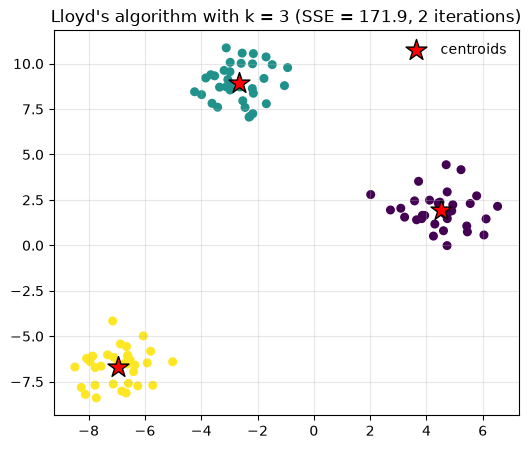

final centroids:
[[ 4.5   1.94]
 [-2.67  8.94]
 [-6.95 -6.68]]


In [2]:
from sklearn.datasets import make_blobs

n_samples = 100
X, y = make_blobs(n_samples=n_samples, centers=3, n_features=2, random_state=SEED)

km = KMeansClustering(k=3).fit(X)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=km.labels, cmap="viridis", s=30)
plt.scatter(km.centroids[:, 0], km.centroids[:, 1], marker="*", s=250, c="red",
            edgecolor="black", label="centroids")
plt.title(f"Lloyd's algorithm with k = 3 (SSE = {km.inertia:.1f}, {km.n_iter_} iterations)")
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.show()

print("final centroids:")
print(np.round(km.centroids, 2))

## Verifying Lemma 2 Numerically

Lemma 2 rewrites the SSE of a set of points — the quantity k-means minimizes — in terms of
*pairwise* distances:

$$
\sum_{i=1}^n \sum_{j>i} \|\mathbf{x}_i - \mathbf{x}_j\|^2
= n \sum_{i=1}^n \|\mathbf{x}_i - \mu\|^2
$$

The left side sums over all $\binom{n}{2}$ pairs of points, the right side is $n$ times the
sum of squared distances of the points to their centroid. The identity is useful whenever an
algorithm can observe only pairwise distances and not the coordinates.

Note what Lemma 2 does **not** say: it is an identity, not an optimality statement. That the
centroid *minimizes* the sum of squared distances is Corollary 1. Below we check that both
sides of Lemma 2 give the same number for one cluster of the clustering above.

In [3]:
from scipy.spatial.distance import cdist


def lemma_2(points):
    """Compute both sides of Lemma 2 and report whether they agree."""
    n = len(points)
    centroid = points.mean(axis=0)
    right = n * np.sum((points - centroid) ** 2)
    left = np.sum(cdist(points, points) ** 2) / 2
    print(f"pairwise sum                         = {left:.6f}")
    print(f"n * sum of squared distances to mean = {right:.6f}")
    print(f"relative difference                  = {abs(left - right) / right:.2e}")
    return left, right


points = X[km.labels == 0]
print(f"cluster 0 contains {len(points)} points")
lemma_2(points)

cluster 0 contains 33 points
pairwise sum                         = 2042.432698
n * sum of squared distances to mean = 2042.432698
relative difference                  = 2.23e-16


(np.float64(2042.4326981762324), np.float64(2042.4326981762329))

## k-Means++ Initialisation

Lloyd's algorithm converges to a local minimum, and which one it reaches depends on the
initial centroids. Two bad configurations are common: two centroids fall inside the same
natural cluster, which is then split in two, and a centroid falls in an empty region, from
which it captures points of several clusters.

**k-means++** (Arthur and Vassilvitskii, 2007) chooses the initial centroids one after
another, each of them far from those already chosen:

1. choose the first centroid uniformly at random from the data;
2. for every point $\mathbf{x}$ compute $D(\mathbf{x})^2$, the squared distance to the
   closest centroid chosen so far;
3. draw the next centroid from the data with probability proportional to
   $D(\mathbf{x})^2$;
4. repeat until $k$ centroids are chosen, then run Lloyd's algorithm as usual.

A point that is already close to a chosen centroid has a small $D^2$ and is therefore
unlikely to be chosen again, so the initial centroids tend to fall in different clusters.
The extra cost is one pass over the data per centroid, negligible compared with the
iterations of Lloyd's algorithm.

The guarantee behind the method is an *approximation* guarantee, not optimality: the
expected SSE of the partition returned after the first iteration is within a factor
$O(\log k)$ of the optimal SSE. Local minima are therefore made less likely, not
impossible, which is why implementations repeat the whole procedure a few times
(`n_init` in scikit-learn, 10 by default) and keep the run with the smallest SSE.

The experiment below runs both initializations 100 times on the same data and compares the
distribution of the final SSE. A run is counted as *bad* if it ends more than 5% above the
best value ever found.

lowest SSE found in any run: 141.74

random      best =  141.74   median =  162.86   worst =  167.16   runs above 1.05 x best =  65%
k-means++   best =  141.74   median =  141.75   worst =  167.17   runs above 1.05 x best =  49%


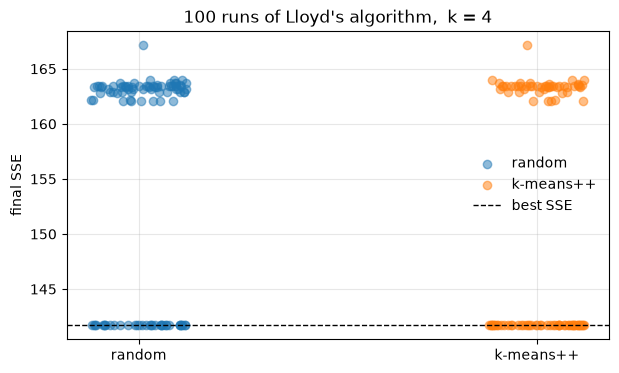

In [4]:
# four blobs, one of them small and squeezed between two large ones: a geometry in which
# a bad initialization merges the small blob into a neighbour
X_hard, _ = make_blobs(n_samples=[100, 100, 100, 25],
                       centers=[[0.0, 0.0], [3.0, 0.0], [6.0, 0.0], [3.0, 1.2]],
                       cluster_std=[0.5, 0.5, 0.5, 0.4],
                       random_state=SEED)

runs = 100
results = {}
for init in ["random", "k-means++"]:
    results[init] = np.array([KMeansClustering(k=4, init=init, seed=s).fit(X_hard).inertia
                              for s in range(runs)])

best = min(v.min() for v in results.values())
print(f"lowest SSE found in any run: {best:.2f}\n")
for init, v in results.items():
    print(f"{init:10s}  best = {v.min():7.2f}   median = {np.median(v):7.2f}   "
          f"worst = {v.max():7.2f}   runs above 1.05 x best = {np.mean(v > 1.05 * best):4.0%}")

jitter = np.random.default_rng(0).uniform(-0.12, 0.12, runs)
plt.figure(figsize=(7, 4))
for (init, v), x0 in zip(results.items(), [0, 1]):
    plt.scatter(x0 + jitter, v, alpha=0.5, label=init)
plt.axhline(best, color="black", lw=1, ls="--", label="best SSE")
plt.xticks([0, 1], ["random", "k-means++"])
plt.ylabel("final SSE")
plt.title(f"{runs} runs of Lloyd's algorithm,  k = 4")
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.show()

Read the two clouds as a statement about the initialization, not about the algorithm: once
initialized, both versions run exactly the same iterations. k-means++ lowers the *typical*
outcome — it lands in the best minimum in about half of the runs instead of roughly a third
— but it does not remove local minima: its worst runs end in exactly the same bad partitions
as random initialization. That is why the method is combined with a handful of restarts.

## Cost

One iteration costs $O(nkd)$: the assignment step computes $n$ distances to each of $k$
centroids in $d$ dimensions, and the update step touches every point once. The number of
iterations is small in practice (tens) but has no useful worst-case bound, which is why we
cap it. `MiniBatchKMeans` (used in [Clustering](Clustering-Part1.ipynb)) replaces the exact
assignment by a random mini-batch per iteration: much faster for large $n$, with almost the
same objective. The exact version can also be accelerated with a $k$-d tree or with
triangle-inequality bounds that skip most distance computations.

## Summary

* k-means minimizes the SSE
  $\sum_{i=1}^{k}\sum_{\mathbf{x}\in C_i}\|\mathbf{x}-\mu_i\|^2$ over partitions into $k$
  non-empty clusters.
* Lemma 1 decomposes the sum of squared distances to an arbitrary point $z$; its corollary
  identifies the centroid as the unique minimizer, which is what justifies the update step.
* Lemma 2 rewrites the SSE through pairwise distances. It is an identity, not an
  optimality statement.
* Lloyd's algorithm alternates assignment and update, so the SSE never increases; a
  non-increasing sequence over a finite set of partitions must stop, at a local minimum.
* The result depends on the initialization: k-means++ spreads the initial centroids and
  greatly reduces bad local minima; implementations cap the iterations and handle empty
  clusters.
* Choosing $k$ is a separate problem, treated in
  [Clustering Validation](Clustering-Validation.ipynb).

## Optional materials related to k-means

* [Data clustering: 50 years beyond K-means - ScienceDirect](https://www.sciencedirect.com/science/article/abs/pii/S0167865509002323)
* [K-Means Factorizaton](https://www.dropbox.com/s/2fsmpj7i7x3rngy/K-Means%20Factorizaton1512.07548.pdf?dl=1)  
* [Balanced K-Means for Clustering | SpringerLink](https://link.springer.com/chapter/10.1007/978-3-662-44415-3_4)
* [M. Amintoosi, (2002) Student’s sectioning using fuzzy inference system (In Persian)](https://www.dropbox.com/s/7ohrff9c6im8bye/1382-StudentSectioning.pdf?dl=1)
* [SE Question: Minimizing the sum of distances between points and a point on the plane?](https://math.stackexchange.com/questions/3037564/minimizing-the-sum-of-distances-between-points-and-a-point-on-the-plane)
* [Geometric Median](https://en.wikipedia.org/wiki/Geometric_median)
* [Weiszfeld's algorithm (Andrew Vázsonyi)](https://en.wikipedia.org/wiki/Andrew_V%C3%A1zsonyi)
